# Phishing URL detection on a second dataset (101K URLs)

Same pipeline as the first notebook, applied unchanged to a different dataset: data audit → leak-free split → classical baselines → deep models (character CNN and character Transformer, TensorFlow/Keras) → ensembles and stacking → confidence intervals → frozen-threshold check → pretrained DistilBERT → error analysis.

**Data:** `url_features_extracted1.csv` (about 101K rows: a raw `URL` column, a `ClassLabel` column and 16 pre-engineered features). **Only the raw URL string and the label are used.** The pre-engineered columns are ignored on purpose: the character models cannot use them, and the earlier audit of this file found them strongly tied to the label (for example `https_flag`), which is a possible source of leakage. **Positive class = phishing**; FPR is measured on legitimate URLs.

**How to run**
* Put the CSV next to the notebook (or edit `DATA` in the first cell). If your column names differ, edit `URL_COL` / `LABEL_COL`.
* This file is the LegitPhish dataset (Mendeley Data, DOI 10.17632/hx4m73v2sf), whose page documents `ClassLabel` 1 = Legitimate, 0 = Phishing, so `PHISH_LABEL = 0` is preset. Still check the label diagnostics the data cell prints.
* There is no score cache for this dataset, so the first run trains everything (about 1-2 h on CPU, much faster on a GPU). Scores are saved to `scores_url101k/`, so later runs only re-evaluate.
* **No numbers from the first dataset appear here.** Every table below is empty until you run it.

In [1]:
import os, re, math, time, warnings, collections
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from urllib.parse import urlparse
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.feature_extraction.text import HashingVectorizer, TfidfTransformer
warnings.filterwarnings("ignore")

RETRAIN = False          # True = ignore cached scores and retrain every model

def first_existing(paths, isdir=False):
    for p in paths:
        if (os.path.isdir(p) if isdir else os.path.isfile(p)): return p
    return None
DATA = first_existing(["url_features_extracted1.csv", "/mnt/user-data/uploads/url_features_extracted1.csv"])
URL_COL, LABEL_COL = "URL", "ClassLabel"   # edit if your column names differ
PHISH_LABEL = 0                           # LegitPhish (Mendeley) documents ClassLabel 1 = Legitimate, 0 = Phishing. None = auto-detect instead
CACHE = first_existing(["scores_url101k"], isdir=True) or "scores_url101k"
os.makedirs(CACHE, exist_ok=True)
print("data:", DATA, "| cache dir:", CACHE, "| RETRAIN =", RETRAIN)

data: /mnt/user-data/uploads/url_features_extracted1.csv | cache dir: scores_url101k | RETRAIN = False


## 1. Data audit

In [2]:
raw0 = pd.read_csv(DATA)
print("columns:", list(raw0.columns)[:20], "| rows:", len(raw0))
raw0 = raw0.dropna(subset=[URL_COL, LABEL_COL]).copy()
raw0[URL_COL] = raw0[URL_COL].astype(str).str.strip()
print("label value counts:", raw0[LABEL_COL].value_counts().to_dict())

# decide which label value means phishing
KWS = ["login", "signin", "verify", "secure", "account", "update", "paypal", "bank", "confirm", "password"]
kw_rate = raw0.groupby(LABEL_COL)[URL_COL].apply(lambda s: s.str.lower().apply(lambda u: any(k in u for k in KWS)).mean())
https_rate = raw0.groupby(LABEL_COL)[URL_COL].apply(lambda s: s.str.startswith("https").mean())
print(pd.DataFrame({"share": raw0[LABEL_COL].value_counts(normalize=True), "phishing-keyword rate": kw_rate, "https rate": https_rate}).round(3))
if PHISH_LABEL is None:
    vals = raw0[LABEL_COL].unique()
    lower = {str(v).lower(): v for v in vals}
    hit = [v for k, v in lower.items() if "phish" in k or "malicious" in k or "bad" in k]
    PHISH_LABEL = hit[0] if hit else kw_rate.idxmax()      # fallback: the class with more phishing-style keywords
print("treating", repr(PHISH_LABEL), "as PHISHING. Look at the table above and at the sample URLs below; if wrong, set PHISH_LABEL.")
for lab in raw0[LABEL_COL].unique():
    print(f"  sample of label {lab!r}:", raw0[raw0[LABEL_COL] == lab][URL_COL].sample(3, random_state=0).tolist())

raw = pd.DataFrame({"url": raw0[URL_COL].values,
                    "label": np.where(raw0[LABEL_COL].values == PHISH_LABEL, "phishing", "legitimate")})
print("rows:", len(raw), "| label counts:", raw.label.value_counts().to_dict())
df = raw.drop_duplicates("url").reset_index(drop=True)
print("exact duplicate URLs removed:", len(raw) - len(df), "| conflicting labels for the same URL:", int((raw.groupby("url").label.nunique() > 1).sum()))
df["y"] = (df.label == "phishing").astype(int).values          # phishing = positive class
y = df.y.values

def host_of(u):
    try: return (urlparse(u if "://" in u else "http://" + u).hostname or "").lower()
    except Exception: return ""
df["host"] = df.url.map(host_of)

# dataset shortcuts: cheap URL properties that may already separate the classes
audit = pd.DataFrame({
    "https": df.url.str.startswith("https"),
    "has a scheme": df.url.str.contains(r"^[a-zA-Z]+://", regex=True),
    "starts with www.": df.url.str.contains(r"^([a-z]+://)?www\.", regex=True),
    "ends with /": df.url.str.endswith("/"),
    "mean length": df.url.str.len()}).groupby(df.label).mean().T
display(audit.round(3))
top = df[df.y == 1].host.value_counts().head(3)
print("most repeated phishing hosts:", top.to_dict())
print("hosts that occur in BOTH classes:", len(set(df[df.y == 1].host) & set(df[df.y == 0].host)))

columns: ['URL', 'url_length', 'has_ip_address', 'dot_count', 'https_flag', 'url_entropy', 'token_count', 'subdomain_count', 'query_param_count', 'tld_length', 'path_length', 'has_hyphen_in_domain', 'number_of_digits', 'tld_popularity', 'suspicious_file_extension', 'domain_name_length', 'percentage_numeric_chars', 'ClassLabel'] | rows: 101219
label value counts: {0.0: 63678, 1.0: 37540}
            share  phishing-keyword rate  https rate
ClassLabel                                          
0.0         0.629                  0.018       0.055
1.0         0.371                  0.003       1.000
treating 0 as PHISHING. Look at the table above and at the sample URLs below; if wrong, set PHISH_LABEL.
  sample of label np.float64(0.0): ['http://123.8.163.4:33987/bin.sh', 'http://182.116.12.190:55415/bin.sh', 'http://182.124.95.65:49439/i']
  sample of label np.float64(1.0): ['https://www.thescotchadvocate.com', 'https://www.sipario.it', 'https://www.easygrass.net']
rows: 101218 | label cou

exact duplicate URLs removed: 346 | conflicting labels for the same URL: 0


label,legitimate,phishing
https,1.000,0.055
has a scheme,1.000,0.980
starts with www.,0.992,0.010
ends with /,0.003,0.014
mean length,27.553,39.433


most repeated phishing hosts: {'nsdm.cumpar-auto-orice-tip.ro': 964, 'playd.healthnlife.pk': 924, 'jask.powerforxes.shop': 770}
hosts that occur in BOTH classes: 1


**Reading the audit (fill in after running)**
* If single hosts repeat hundreds of times, a random split would put near-identical URLs in train and test, so the split below is **grouped by host** regardless.
* If `https`, a leading `www.`, or a missing scheme differs sharply between the classes, those cues are a **dataset shortcut**. Every model is therefore also trained on a **stripped** URL (scheme and `www.` removed) to show how much of the score comes from the shortcut. This file is the one where an earlier check flagged `https_flag` as strongly tied to the label, so expect the raw-versus-stripped gap to matter.
* The dataset page says the legitimate URLs were scraped from sources such as Wikipedia and Stack Overflow. If so, the legitimate class may be dominated by a few hosts. Check the audit output (most repeated hosts and the split sizes in the next cell): a host-grouped split can then put most legitimate URLs on one side, and models may learn the site rather than anything about phishing.
* This dataset has far fewer legitimate URLs than the first one (see the split sizes in the next cell), so the 0.1% FPR column rests on very few URLs. Treat it as indicative only; the bootstrap intervals in section 9.1 show how wide it is.

In [3]:
# host-grouped split: 70 / 10 / 20, no host in two splits
dev_i, te_i = next(GroupShuffleSplit(1, test_size=0.2, random_state=42).split(df, df.y, df.host))
a, b = next(GroupShuffleSplit(1, test_size=0.125, random_state=42).split(df.iloc[dev_i], df.y.iloc[dev_i], df.host.iloc[dev_i]))
tr_i, va_i = dev_i[a], dev_i[b]
assert not (set(df.host.iloc[tr_i]) & set(df.host.iloc[te_i])) and not (set(df.host.iloc[va_i]) & set(df.host.iloc[te_i]))
print(f"train {len(tr_i):,} | val {len(va_i):,} | test {len(te_i):,} | legitimate URLs in test (negatives): {(y[te_i]==0).sum():,}")
print("FPR 0.1% allows", int(math.floor(0.001 * (y[te_i] == 0).sum())), "false alarms on the test set")

idx_file = os.path.join(CACHE, "idx.npy")
if os.path.exists(idx_file):                                   # integrity check against the cached run
    c_tr, c_va, c_te = [np.asarray(x, dtype=np.int64) for x in np.load(idx_file, allow_pickle=True)]
    assert (c_tr == tr_i).all() and (c_va == va_i).all() and (c_te == te_i).all(), "split differs from the cached run"
    print("split identical to the cached run")
else:
    np.save(idx_file, np.array([tr_i, va_i, te_i], dtype=object), allow_pickle=True)

strip = lambda u: re.sub(r"^www\d*\.", "", re.sub(r"^[a-zA-Z]+://", "", u))
urls = df.url.tolist(); urls_s = [strip(u) for u in urls]

train 71,562 | val 9,603 | test 19,707 | legitimate URLs in test (negatives): 7,449
FPR 0.1% allows 7 false alarms on the test set
split identical to the cached run


## 2. Metric

In [4]:
def tpr_at_fpr(y_pos, s, t):
    """TPR when at most floor(t * N_negatives) legitimate URLs score strictly above the threshold."""
    neg = np.sort(s[y_pos == 0])[::-1]; k = int(math.floor(t * len(neg)))
    thr = neg[k] if k < len(neg) else -np.inf
    return float((s[y_pos == 1] > thr).mean() * 100)

yt = y[te_i]
def row(name, s):
    return {"Model": name, "AUC": round(roc_auc_score(yt, s), 4), "TPR@10%": round(tpr_at_fpr(yt, s, .10), 2),
            "TPR@5%": round(tpr_at_fpr(yt, s, .05), 2), "TPR@1%": round(tpr_at_fpr(yt, s, .01), 2), "TPR@0.1%": round(tpr_at_fpr(yt, s, .001), 2)}
V, T = {}, {}      # validation / test scores of every model (phishing = higher)

## 3. Classical baselines (character n-gram logistic regression, lexical-feature XGBoost, word n-gram LR)

In [5]:
cls_v, cls_t = os.path.join(CACHE, "scores_val.npy"), os.path.join(CACHE, "test_scores.npy")
if os.path.exists(cls_v) and os.path.exists(cls_t) and not RETRAIN:
    cv_ = np.load(cls_v, allow_pickle=True).item(); ct_ = np.load(cls_t, allow_pickle=True).item()
    for k in cv_: V[k], T[k] = cv_[k], ct_[k]
    print("loaded cached classical scores:", list(cv_))
else:
    from xgboost import XGBClassifier
    def char_linear(name, texts):
        texts = np.array(texts, dtype=object)
        hv = HashingVectorizer(analyzer="char", ngram_range=(3, 5), n_features=2 ** 21, alternate_sign=False, norm=None, lowercase=True, dtype=np.float32)
        Xtr = hv.transform(texts[tr_i]); tf_ = TfidfTransformer(sublinear_tf=True).fit(Xtr); Xtr = tf_.transform(Xtr)
        m = SGDClassifier(loss="log_loss", alpha=2e-7, max_iter=25, tol=None, random_state=0).fit(Xtr, y[tr_i])
        V[name] = m.decision_function(tf_.transform(hv.transform(texts[va_i]))); T[name] = m.decision_function(tf_.transform(hv.transform(texts[te_i])))
    char_linear("charNgram-LR (raw URL)", urls); char_linear("charNgram-LR (scheme/www stripped)", urls_s)

    KW = ["paypal","login","signin","secure","account","update","verify","bank","ebay","confirm","webscr","password","apple","amazon","microsoft"]
    SHORT = {"bit.ly","tinyurl.com","goo.gl","t.co","ow.ly","is.gd","buff.ly","tiny.cc"}
    def ent(s):
        if not s: return 0.0
        c = collections.Counter(s); n = len(s); return -sum(v / n * math.log2(v / n) for v in c.values())
    def feats(u, stripped):
        s = strip(u) if stripped else u
        p = urlparse(u if "://" in u else "http://" + u); h = p.hostname or ""; path = p.path or ""; q = p.query or ""; parts = h.split(".")
        f = [len(s), len(h), len(path), len(q), sum(c.isdigit() for c in s), sum(c.isalpha() for c in s), s.count("."), s.count("-"), s.count("_"),
             s.count("/"), s.count("?"), s.count("="), s.count("&"), s.count("%"), s.count("@"), s.count("//"), len(parts), h.count("-"),
             sum(c.isdigit() for c in h), int(bool(re.fullmatch(r"\d+\.\d+\.\d+\.\d+", h))), int(h in SHORT), ent(s), ent(h), ent(path),
             max((len(x) for x in parts), default=0), len(parts[-1]) if parts else 0, int(":" in (p.netloc or "")),
             sum(k in s.lower() for k in KW), sum(k in h for k in KW),
             int(path.lower().endswith((".php",".html",".htm",".asp",".aspx",".jsp"))), len(path.split("/")) - 1]
        if not stripped: f += [int(u.startswith("https")), int(bool(re.match(r"^[a-z]+://www\d*\.", u)))]
        return f
    lg = lambda p: np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))
    for nm, st in [("lexical-XGB (raw URL)", False), ("lexical-XGB (scheme/www stripped)", True)]:
        M = np.array([feats(u, st) for u in urls], dtype=np.float32)
        m = XGBClassifier(n_estimators=500, learning_rate=0.08, max_depth=8, subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                          eval_metric="logloss", n_jobs=-1, random_state=0).fit(M[tr_i], y[tr_i])
        V[nm], T[nm] = lg(m.predict_proba(M[va_i])[:, 1]), lg(m.predict_proba(M[te_i])[:, 1])
    np.save(cls_v, V, allow_pickle=True); np.save(cls_t, T, allow_pickle=True)

wf = os.path.join(CACHE, "dl_wordlr.npy")                       # word n-gram LR
if os.path.exists(wf) and not RETRAIN:
    d = np.load(wf, allow_pickle=True).item(); V["word-ngram LR"], T["word-ngram LR"] = d["val"], d["test"]
else:
    low = np.array([u.lower() for u in urls], dtype=object)
    hv = HashingVectorizer(analyzer="word", token_pattern=r"[a-z0-9]+", ngram_range=(1, 3), n_features=2 ** 21, alternate_sign=False, norm=None, dtype=np.float32)
    Xtr = hv.transform(low[tr_i]); tf_ = TfidfTransformer(sublinear_tf=True).fit(Xtr)
    m = SGDClassifier(loss="log_loss", alpha=5e-7, max_iter=25, tol=None, random_state=0).fit(tf_.transform(Xtr), y[tr_i])
    V["word-ngram LR"] = m.decision_function(tf_.transform(hv.transform(low[va_i]))); T["word-ngram LR"] = m.decision_function(tf_.transform(hv.transform(low[te_i])))
    np.save(wf, {"val": V["word-ngram LR"], "test": T["word-ngram LR"]}, allow_pickle=True)

display(pd.DataFrame([row(n, T[n]) for n in ["charNgram-LR (raw URL)", "lexical-XGB (raw URL)", "word-ngram LR", "charNgram-LR (scheme/www stripped)", "lexical-XGB (scheme/www stripped)"]]).set_index("Model"))

loaded cached classical scores: ['charNgram-LR (raw URL)', 'charNgram-LR (scheme/www stripped)', 'lexical-XGB (raw URL)', 'lexical-XGB (scheme/www stripped)']


,AUC,TPR@10%,TPR@5%,TPR@1%,TPR@0.1%
Model,,,,,
charNgram-LR (raw URL),1.0000,100.0,100.00,99.99,99.94
lexical-XGB (raw URL),1.0000,100.0,100.00,100.00,99.91
word-ngram LR,1.0000,100.0,100.00,100.00,99.90
charNgram-LR (scheme/www stripped),0.9997,100.0,99.98,99.92,91.70
lexical-XGB (scheme/www stripped),1.0000,100.0,100.00,99.99,99.61


## 4. Deep models (TensorFlow / Keras)

* **Character CNN:** byte embeddings → three parallel conv stacks (kernel 3, 5, 7) → max + average pooling → MLP.
* **Character Transformer (from scratch):** 2 pre-norm encoder layers, 4 heads, d=64, learned positions, masked mean + max pooling. No pretraining, so it needs far more data than it gets here.
* **Loss:** binary cross-entropy, optionally plus a **partial-AUC term** that pushes every phishing logit above the highest-scoring legitimate logits in the batch (`lam > 0`).
* CPU budget: the CNN trains on up to 100,000 URLs (here, the whole training split) and the Transformer on up to 60,000, 3 epochs, one seed per run.

In [6]:
L = 128
def encode(texts, idx):
    a = np.zeros((len(idx), L), dtype=np.int32)
    for r, i in enumerate(idx):
        b = texts[i].encode("utf-8", "ignore")[:L]; a[r, :len(b)] = np.frombuffer(b, dtype=np.uint8).astype(np.int32) + 1
    return a

def build_models():
    import tensorflow as tf
    from tensorflow.keras import layers as Ly
    def char_cnn():
        i = Ly.Input((L,), dtype="int32"); z = Ly.Embedding(257, 32)(i); outs = []
        for w in (3, 5, 7):
            c = Ly.Conv1D(96, w, padding="same", activation="gelu")(z); c = Ly.Conv1D(96, w, padding="same", activation="gelu")(c)
            outs += [Ly.GlobalMaxPooling1D()(c), Ly.GlobalAveragePooling1D()(c)]
        h = Ly.Dropout(0.3)(Ly.Concatenate()(outs)); h = Ly.Dropout(0.3)(Ly.Dense(192, activation="gelu")(h))
        return tf.keras.Model(i, Ly.Dense(1)(h))
    class CharTfm(tf.keras.Model):
        def __init__(self, d=64, heads=4, nl=2):
            super().__init__()
            self.tok = Ly.Embedding(257, d); self.pos = Ly.Embedding(L, d)
            self.n1 = [Ly.LayerNormalization() for _ in range(nl)]; self.n2 = [Ly.LayerNormalization() for _ in range(nl)]
            self.att = [Ly.MultiHeadAttention(heads, d // heads) for _ in range(nl)]
            self.f1 = [Ly.Dense(2 * d, activation="gelu") for _ in range(nl)]; self.f2 = [Ly.Dense(d) for _ in range(nl)]
            self.dr = Ly.Dropout(0.1); self.nf = Ly.LayerNormalization()
            self.h1 = Ly.Dense(128, activation="gelu"); self.dh = Ly.Dropout(0.2); self.out = Ly.Dense(1)
        def call(self, x, training=False):
            mask = tf.cast(x > 0, tf.float32); am = tf.cast(mask[:, None, :], tf.bool)
            z = self.tok(x) + self.pos(tf.range(L)[None, :])
            for i in range(len(self.att)):
                h = self.n1[i](z); z = z + self.dr(self.att[i](h, h, attention_mask=am), training=training)
                z = z + self.dr(self.f2[i](self.f1[i](self.n2[i](z))), training=training)
            z = self.nf(z); m = mask[:, :, None]
            mean = tf.reduce_sum(z * m, 1) / tf.maximum(tf.reduce_sum(m, 1), 1.0); mx = tf.reduce_max(z + (m - 1.0) * 1e4, 1)
            return self.out(self.dh(self.h1(tf.concat([mean, mx], -1)), training=training))
    def char_transformer():
        m = CharTfm(); m(np.zeros((2, L), dtype=np.int32)); return m
    return tf, char_cnn, char_transformer

def train_dl(tag, arch, variant, ntrain, epochs, lam, seed=0, bs=256):
    """Train (or load cached scores). Returns (val_logits, test_logits)."""
    f = os.path.join(CACHE, f"dl_{tag}.npy")
    if os.path.exists(f) and not RETRAIN:
        d = np.load(f, allow_pickle=True).item(); return d["val"], d["test"]
    tf, char_cnn, char_transformer = build_models()
    tf.random.set_seed(seed); np.random.seed(seed)
    texts = urls if variant == "raw" else urls_s
    sub = np.random.default_rng(0).permutation(tr_i)[:ntrain]
    Xtr, Xva, Xte = encode(texts, sub), encode(texts, va_i), encode(texts, te_i); ytr = y[sub].astype(np.float32)
    model = char_cnn() if arch == "cnn" else char_transformer()
    def pauc(logit, yb, frac=0.05, margin=1.0):
        pos = tf.boolean_mask(logit, yb > 0.5); neg = tf.boolean_mask(logit, yb < 0.5)
        def g():
            k = tf.minimum(tf.maximum(1, tf.cast(tf.math.ceil(frac * tf.cast(tf.size(neg), tf.float32)), tf.int32)), tf.size(neg))
            return tf.reduce_mean(tf.nn.softplus(margin - (pos[:, None] - tf.math.top_k(neg, k=k).values[None, :])))
        return tf.cond(tf.logical_and(tf.size(pos) > 0, tf.size(neg) > 0), g, lambda: tf.constant(0.0))
    steps = epochs * math.ceil(len(Xtr) / bs); lr = 2e-3 if arch == "cnn" else 1e-3
    opt = tf.keras.optimizers.AdamW(tf.keras.optimizers.schedules.CosineDecay(lr, steps, alpha=0.02), weight_decay=1e-4)
    @tf.function
    def step(x, yb):
        with tf.GradientTape() as tape:
            lg_ = tf.squeeze(model(x, training=True), -1)
            loss = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(labels=yb, logits=lg_))
            if lam > 0: loss += lam * pauc(lg_, yb)
        g = tape.gradient(loss, model.trainable_variables); g, _ = tf.clip_by_global_norm(g, 1.0)
        opt.apply_gradients(zip(g, model.trainable_variables)); return loss
    t0 = time.time()
    for ep in range(epochs):
        perm = np.random.default_rng(ep).permutation(len(Xtr)); tot = n = 0
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]; tot += float(step(Xtr[b], ytr[b])); n += 1
        print(f"{tag}: epoch {ep+1}/{epochs} loss {tot/n:.4f} ({time.time()-t0:.0f}s)")
    pred = lambda X: model.predict(X, batch_size=1024, verbose=0)[:, 0]
    sv, st = pred(Xva), pred(Xte); np.save(f, {"val": sv, "test": st}, allow_pickle=True); return sv, st

NCNN, NTFM = min(100000, len(tr_i)), min(60000, len(tr_i))   # this dataset is smaller, so the CNN uses the whole training set
RUNS = [  # name shown in tables,          cache tag,           arch,          variant,    ntrain, epochs, lam, seed
    ("CNN BCE+pAUC (raw, seed 0)",      "cnn_raw_pauc",       "cnn",         "raw",      NCNN, 3, 1.0, 0),
    ("CNN BCE only (raw, seed 0)",      "cnn_raw_bce",        "cnn",         "raw",      NCNN, 3, 0.0, 0),
    ("CNN BCE only (raw, seed 1)",      "cnn_raw_bce_s1",     "cnn",         "raw",      NCNN, 3, 0.0, 1),
    ("CNN BCE only (raw, seed 2)",      "cnn_raw_bce_s2",     "cnn",         "raw",      NCNN, 3, 0.0, 2),
    ("char-Transformer BCE+pAUC (raw)", "tfm_raw_pauc",       "transformer", "raw",      NTFM,  3, 1.0, 0),
    ("CNN BCE+pAUC (stripped)",         "cnn_stripped_pauc",  "cnn",         "stripped", NCNN, 3, 1.0, 0)]
for name, tag, arch, variant, ntr, ep, lam, seed in RUNS:
    V[name], T[name] = train_dl(tag, arch, variant, ntr, ep, lam, seed)
display(pd.DataFrame([row(n[0], T[n[0]]) for n in RUNS]).set_index("Model"))

I0000 00:00:1795535181.656437      97 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795535193.745500      97 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 AMX_FP16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795535200.564782      97 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


tfm_raw_pauc: epoch 1/3 loss 0.0289 (196s)


tfm_raw_pauc: epoch 2/3 loss 0.0030 (377s)


tfm_raw_pauc: epoch 3/3 loss 0.0010 (552s)


cnn_stripped_pauc: epoch 1/3 loss 0.1021 (112s)


cnn_stripped_pauc: epoch 2/3 loss 0.0082 (220s)


cnn_stripped_pauc: epoch 3/3 loss 0.0052 (328s)


,AUC,TPR@10%,TPR@5%,TPR@1%,TPR@0.1%
Model,,,,,
"CNN BCE+pAUC (raw, seed 0)",1.0000,100.00,100.00,99.99,99.43
"CNN BCE only (raw, seed 0)",1.0000,100.00,100.00,100.00,99.75
"CNN BCE only (raw, seed 1)",1.0000,100.00,100.00,100.00,99.60
"CNN BCE only (raw, seed 2)",1.0000,100.00,100.00,100.00,99.60
char-Transformer BCE+pAUC (raw),1.0000,100.00,100.00,99.99,99.50
CNN BCE+pAUC (stripped),0.9999,99.99,99.99,99.98,99.04


**Reading the CNN rows (fill in after running).** Compare the three BCE-only seeds to see the seed-to-seed spread, and do not read a difference between two single runs (for example BCE vs BCE+pAUC) as evidence unless it is clearly larger than that spread. The 0.1% column is decided by only a handful of legitimate URLs on this dataset, so it is the noisiest column.

## 5. Ensembles
Each model's logits are z-scored with its **validation** mean/std, then combined. The stacker is a logistic regression fitted on **validation** scores only; the test set is never used for fitting. Caveat: the member lists were fixed after looking at single-model results (the Transformer was weak, so it is left out of ENS-A and shown separately in ENS-B).

In [7]:
z = lambda n, S: (S[n] - V[n].mean()) / (V[n].std() + 1e-9)
avg = lambda names: np.mean([z(n, T) for n in names], 0)
cls_raw = ["charNgram-LR (raw URL)", "lexical-XGB (raw URL)", "word-ngram LR"]
cnns = [r[0] for r in RUNS if r[0].startswith("CNN") and "(raw" in r[0]]
tfm = "char-Transformer BCE+pAUC (raw)"
strn = ["charNgram-LR (scheme/www stripped)", "lexical-XGB (scheme/www stripped)", "CNN BCE+pAUC (stripped)"]

E = {}
E["ENS-A: classical (3) + 4 CNNs"] = avg(cls_raw + cnns)
E["ENS-B: ENS-A + Transformer"] = avg(cls_raw + cnns + [tfm])
E["ENS-C: CNN weight x2"] = (avg(cls_raw) * len(cls_raw) + 2 * avg(cnns) * len(cnns)) / (len(cls_raw) + 2 * len(cnns))
E["ENS-STRIPPED: charLR + XGB + CNN (no https/www)"] = avg(strn)
names = cls_raw + cnns                                          # stacker inputs
Mv = np.column_stack([z(n, V) for n in names]); Mt = np.column_stack([z(n, T) for n in names])
meta = LogisticRegression(C=1.0, max_iter=2000).fit(Mv, y[va_i])
E["STACK: logistic meta-learner (fit on validation)"] = meta.decision_function(Mt)
print("stacker weights:", {n: round(float(w), 2) for n, w in zip(names, meta.coef_[0])})

final = pd.DataFrame([row(n, T[n]) for n in cls_raw[:2] + ["word-ngram LR"] + cnns + [tfm]] + [row(n, s) for n, s in E.items()]).set_index("Model")
display(final)
final.to_csv("final_results.csv")

stacker weights: {'charNgram-LR (raw URL)': 2.04, 'lexical-XGB (raw URL)': 1.69, 'word-ngram LR': 1.9, 'CNN BCE+pAUC (raw, seed 0)': 0.43, 'CNN BCE only (raw, seed 0)': 0.96, 'CNN BCE only (raw, seed 1)': 0.93, 'CNN BCE only (raw, seed 2)': 1.03}


,AUC,TPR@10%,TPR@5%,TPR@1%,TPR@0.1%
Model,,,,,
charNgram-LR (raw URL),1.0,100.0,100.0,99.99,99.94
lexical-XGB (raw URL),1.0,100.0,100.0,100.00,99.91
word-ngram LR,1.0,100.0,100.0,100.00,99.90
"CNN BCE+pAUC (raw, seed 0)",1.0,100.0,100.0,99.99,99.43
"CNN BCE only (raw, seed 0)",1.0,100.0,100.0,100.00,99.75
"CNN BCE only (raw, seed 1)",1.0,100.0,100.0,100.00,99.60
"CNN BCE only (raw, seed 2)",1.0,100.0,100.0,100.00,99.60
char-Transformer BCE+pAUC (raw),1.0,100.0,100.0,99.99,99.50
ENS-A: classical (3) + 4 CNNs,1.0,100.0,100.0,100.00,99.94


## 6. Low-FPR ROC

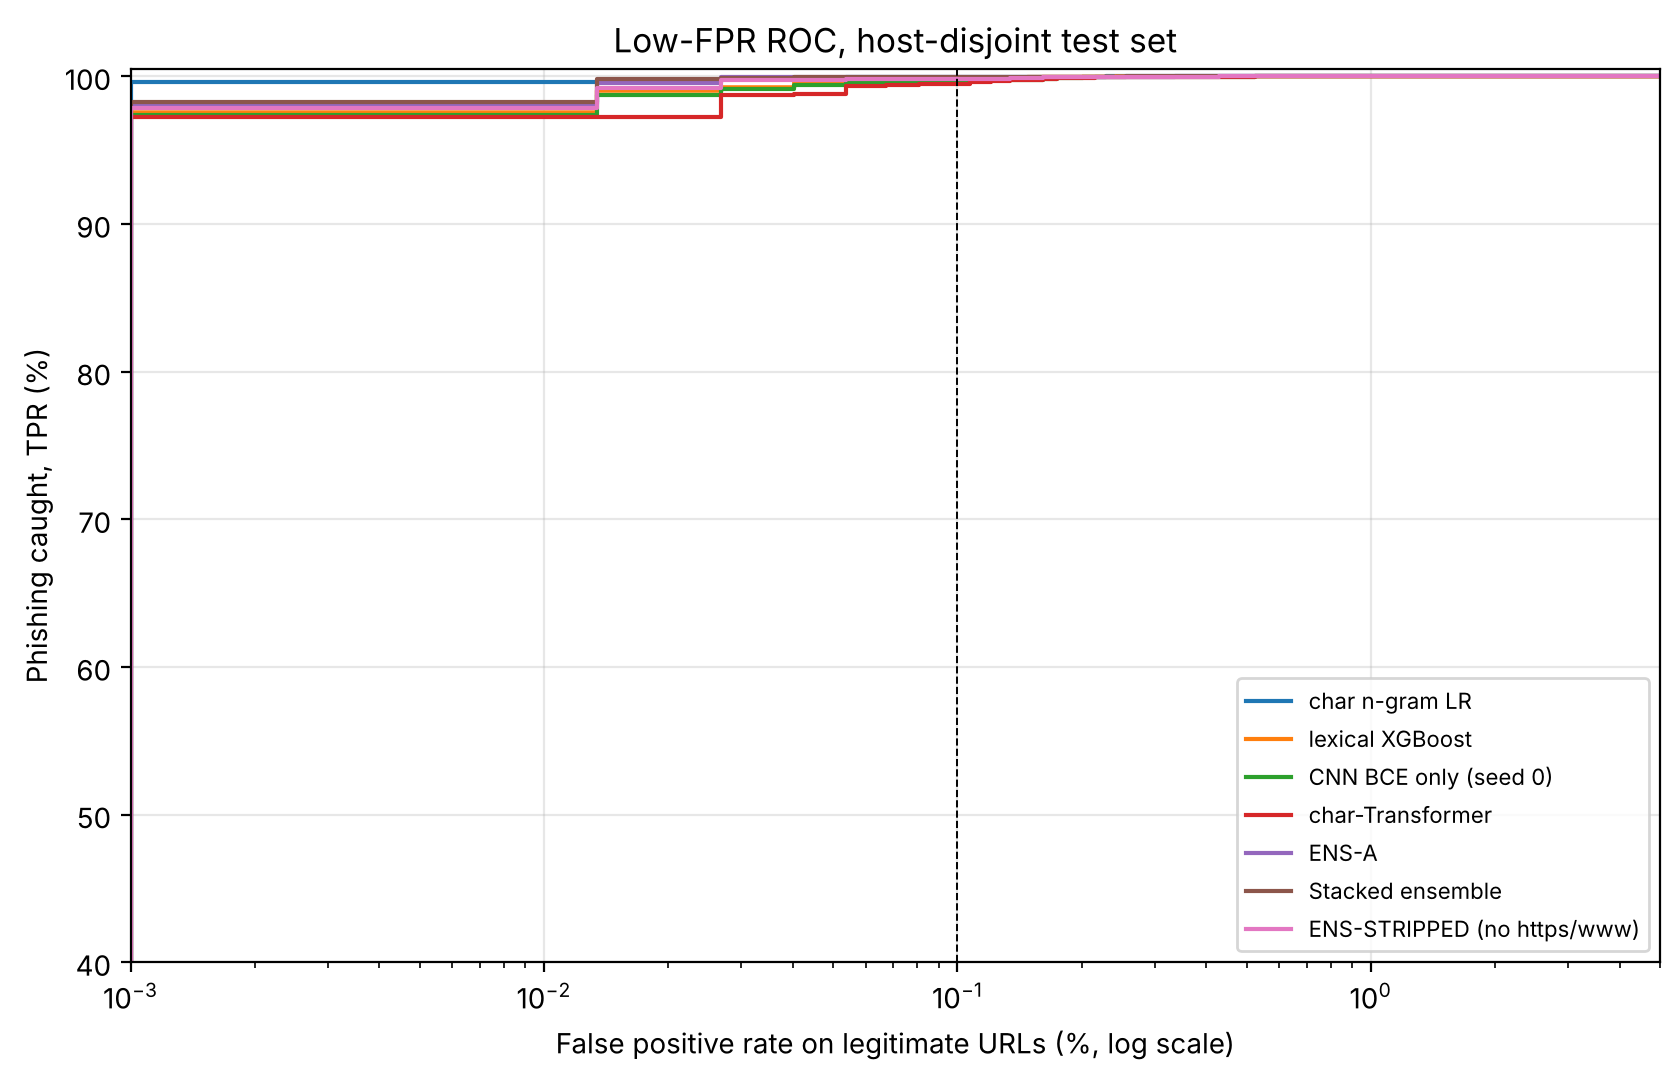

In [8]:
plt.figure(figsize=(8.5, 5.5))
for n, s in [("char n-gram LR", T["charNgram-LR (raw URL)"]), ("lexical XGBoost", T["lexical-XGB (raw URL)"]),
             ("CNN BCE only (seed 0)", T["CNN BCE only (raw, seed 0)"]), ("char-Transformer", T[tfm]),
             ("ENS-A", E["ENS-A: classical (3) + 4 CNNs"]), ("Stacked ensemble", E["STACK: logistic meta-learner (fit on validation)"]),
             ("ENS-STRIPPED (no https/www)", E["ENS-STRIPPED: charLR + XGB + CNN (no https/www)"])]:
    f, t, _ = roc_curve(yt, s); plt.semilogx(np.maximum(f, 1e-5) * 100, t * 100, label=n)
plt.axvline(0.1, color="k", ls="--", lw=0.7)
plt.xlim(1e-3, 5); plt.ylim(40, 100.5); plt.grid(alpha=.3); plt.legend(fontsize=8, loc="lower right")
plt.xlabel("False positive rate on legitimate URLs (%, log scale)"); plt.ylabel("Phishing caught, TPR (%)")
plt.title("Low-FPR ROC, host-disjoint test set"); plt.tight_layout(); plt.show()

## 7. Error analysis (stacked ensemble)

In [9]:
s = E["STACK: logistic meta-learner (fit on validation)"]; u_te = np.array(urls, dtype=object)[te_i]
neg = np.where(yt == 0)[0]; order = neg[np.argsort(-s[neg])]; thr = s[order[int(math.floor(0.001 * len(neg)))]]
print("Legitimate URLs the model is most sure are phishing (they set the 0.1% threshold):")
for i in order[:12]: print(f"  {s[i]:6.2f}  {u_te[i][:100]}")
pos = np.where(yt == 1)[0]; missed = pos[s[pos] <= thr]
print(f"\nPhishing missed at 0.1% FPR: {len(missed):,} of {len(pos):,} ({len(missed)/len(pos)*100:.1f}%)")
print("most frequent hosts among missed phishing:", collections.Counter(host_of(u_te[i]) for i in missed).most_common(6))
print("\nrandom sample of missed phishing URLs:")
if len(missed): 
    for i in np.random.default_rng(1).choice(missed, min(8, len(missed)), replace=False): print(f"  {s[i]:6.2f}  {u_te[i][:100]}")
else: print("  (none: no phishing URL falls below the 0.1% threshold)")

Legitimate URLs the model is most sure are phishing (they set the 0.1% threshold):
    4.08  http://www.kelloggs.com/en_US/home.html
    2.51  https://cmat.nta.nic.in/
    1.17  https://getbootstrap.com/
    0.87  https://trends.netcraft.com/topsites
    0.74  https://open.spotify.com/
    0.65  https://commonhelp.virginia.gov/
    0.47  https://today.yougov.com/ratings/entertainment/popularity/news-websites/all
    0.35  https://time.com/4960202/most-influential-websites/
    0.07  https://provaromarketing.com/12-popular-websites-world/
    0.00  https://www.toppotdoughnuts.com/?srsltid=AfmBOorroQlZ5bciwxlQv5V3p9IlJJg8V0iq2h__0-GpLiKhdeor05Ah
   -0.04  https://trends.google.com/trends/
   -0.04  https://tophat.com/

Phishing missed at 0.1% FPR: 5 of 12,258 (0.0%)
most frequent hosts among missed phishing: [('www.hercvlesconcrete.com', 3), ('www.apijs.djibysoft.com', 1), ('www.eb2a.live', 1)]

random sample of missed phishing URLs:
   -0.41  https://www.hercvlesconcrete.com/Document.zi

## 8. Takeaways and caveats

Write these after running; nothing here is carried over from the first dataset. Questions to answer from the tables:

1. Do the deep models and the ensembles beat the classical baselines at 1% and 0.1% target FPR, and by more than the intervals in section 9.1?
2. Does the pAUC loss help, relative to the spread across the BCE-only seeds?
3. How does the from-scratch Transformer compare, and does DistilBERT (section 10) change that?
4. How large is the raw-versus-stripped gap? Quote the stripped numbers as the generalisation estimate.
5. How many legitimate URLs decide the 0.1% column? (Printed in the split cell.)
6. Does the ranking of methods agree with the first dataset? Agreement is evidence the method ordering is not a quirk of one dataset; the absolute numbers are not comparable across datasets.

## 9. Added sections: uncertainty, honest thresholds, pretrained transformer

Everything above is the original notebook, unchanged. Sections 9-11 close three gaps:

1. **No confidence intervals** (the title promised them). Section 9.1 adds a *host-cluster bootstrap*: whole hosts are resampled, because URLs from one host are not independent.
2. **Thresholds were picked on the test set.** `tpr_at_fpr` sets the threshold from the *test* negatives, which is an oracle choice. Section 9.2 picks the threshold on **validation only**, freezes it, and reports what really happens on test (the realised FPR and TPR).
3. **No pretrained model.** Section 10 fine-tunes DistilBERT on the raw URL (not run in this package; see the flag `RUN_BERT`).

Nothing in this notebook was executed when it was produced, because the CSV was not available. Sections 9.1 and 9.2 run in about a minute once the scores exist; section 10 needs a GPU for about 30-60 minutes.

### 9.1 Confidence intervals (host-cluster bootstrap, 95%)

In [10]:
B_BOOT = 500                                   # raise to 2000 for the final report
h_te = df.host.iloc[te_i].values
_, hcode = np.unique(h_te, return_inverse=True); n_hosts = int(hcode.max()) + 1
TARGETS = (.10, .05, .01, .001)

M91 = {"charNgram-LR (raw URL)": T["charNgram-LR (raw URL)"],
       "CNN BCE only (raw, seed 0)": T["CNN BCE only (raw, seed 0)"],
       "ENS-A": E["ENS-A: classical (3) + 4 CNNs"],
       "STACK": E["STACK: logistic meta-learner (fit on validation)"],
       "ENS-STRIPPED (no https/www)": E["ENS-STRIPPED: charLR + XGB + CNN (no https/www)"]}

res = {m: {t: [] for t in TARGETS} for m in M91}
for b in range(B_BOOT):
    rs = np.random.default_rng(1000 + b)
    w = np.bincount(rs.integers(0, n_hosts, n_hosts), minlength=n_hosts)[hcode]
    idx = np.repeat(np.arange(len(yt)), w)                       # same resample for every model -> paired comparison
    for m, S in M91.items():
        for t in TARGETS: res[m][t].append(tpr_at_fpr(yt[idx], S[idx], t))

rows = []
for m, S in M91.items():
    r = {"Model": m}
    for t in TARGETS:
        lo, hi = np.percentile(res[m][t], [2.5, 97.5])
        r[f"TPR@{t*100:g}%"] = f"{tpr_at_fpr(yt, S, t):.1f}  [{lo:.1f}, {hi:.1f}]"
    rows.append(r)
ci_table = pd.DataFrame(rows).set_index("Model"); display(ci_table); ci_table.to_csv("final_results_with_CI.csv")

# paired difference: is the stacker really better than the best single model at 0.1%?
d = np.array(res["STACK"][.001]) - np.array(res["charNgram-LR (raw URL)"][.001])
print(f"STACK minus charNgram-LR at 0.1%: median {np.median(d):.1f} pts, 95% interval [{np.percentile(d,2.5):.1f}, {np.percentile(d,97.5):.1f}]")

,TPR@10%,TPR@5%,TPR@1%,TPR@0.1%
Model,,,,
charNgram-LR (raw URL),"100.0 [100.0, 100.0]","100.0 [100.0, 100.0]","100.0 [100.0, 100.0]","99.9 [99.9, 100.0]"
"CNN BCE only (raw, seed 0)","100.0 [100.0, 100.0]","100.0 [100.0, 100.0]","100.0 [100.0, 100.0]","99.7 [99.4, 99.9]"
ENS-A,"100.0 [100.0, 100.0]","100.0 [100.0, 100.0]","100.0 [100.0, 100.0]","99.9 [99.9, 100.0]"
STACK,"100.0 [100.0, 100.0]","100.0 [100.0, 100.0]","100.0 [100.0, 100.0]","100.0 [99.9, 100.0]"
ENS-STRIPPED (no https/www),"100.0 [100.0, 100.0]","100.0 [100.0, 100.0]","100.0 [100.0, 100.0]","99.8 [99.7, 100.0]"


STACK minus charNgram-LR at 0.1%: median 0.0 pts, 95% interval [-0.0, 0.1]


### 9.2 Validation-calibrated thresholds (the deployment-style check)

For each model the threshold is the score that lets through `floor(t * N_negatives)` legitimate URLs **on the validation set**. It is then frozen and applied once to the test set. Report the *realised* test FPR next to the TPR: if the realised FPR is above the target, the target was not met.

Caveats written into the code: the stacker is fitted on validation, so its validation scores are optimistic. We therefore use **cross-fitted** (5-fold, host-grouped) stacker scores on validation to choose its threshold. On this dataset the validation set has only a few thousand legitimate URLs, so a 0.1% target is decided by single-digit numbers of URLs: expect a very noisy threshold and prefer the 1% and 5% rows.

In [11]:
from sklearn.model_selection import GroupKFold
yv = y[va_i]; gv = df.host.iloc[va_i].values
avgV = lambda names: np.mean([z(n, V) for n in names], 0)

cv_stack = np.zeros(len(yv))
for a_, b_ in GroupKFold(5).split(Mv, yv, gv):
    cv_stack[b_] = LogisticRegression(C=1.0, max_iter=2000).fit(Mv[a_], yv[a_]).decision_function(Mv[b_])

CAND = {"charNgram-LR (raw URL)": (V["charNgram-LR (raw URL)"], T["charNgram-LR (raw URL)"]),
        "CNN BCE only (raw, seed 0)": (V["CNN BCE only (raw, seed 0)"], T["CNN BCE only (raw, seed 0)"]),
        "ENS-A": (avgV(cls_raw + cnns), E["ENS-A: classical (3) + 4 CNNs"]),
        "STACK (cross-fitted val)": (cv_stack, E["STACK: logistic meta-learner (fit on validation)"]),
        "ENS-STRIPPED (no https/www)": (avgV(strn), E["ENS-STRIPPED: charLR + XGB + CNN (no https/www)"])}

def frozen_eval(sv, st, t):
    neg = np.sort(sv[yv == 0])[::-1]; k = int(math.floor(t * len(neg))); thr = neg[k]
    fp = int(((st > thr) & (yt == 0)).sum()); tp = int(((st > thr) & (yt == 1)).sum())
    return thr, 100 * fp / (yt == 0).sum(), 100 * tp / (yt == 1).sum(), fp

rows = []
for m, (sv, st) in CAND.items():
    for t in (.05, .01, .001):
        thr, fpr, tpr, fp = frozen_eval(sv, st, t)
        rows.append({"Model": m, "target FPR %": t * 100, "val threshold": round(float(thr), 3),
                     "test FPR % (realised)": round(fpr, 3), "false alarms on test": fp, "test TPR %": round(tpr, 2)})
frozen = pd.DataFrame(rows); display(frozen); frozen.to_csv("frozen_threshold_results.csv", index=False)
print("Read as: 'X% TPR at a target FPR of Y%, realised test FPR Z%'.")

,Model,target FPR %,val threshold,test FPR % (realised),false alarms on test,test TPR %
0,charNgram-LR (raw URL),5.0,-5.748,4.511,336,100.00
1,charNgram-LR (raw URL),1.0,-4.653,1.248,93,100.00
2,charNgram-LR (raw URL),0.1,-0.868,0.148,11,99.94
3,"CNN BCE only (raw, seed 0)",5.0,-12.283,4.215,314,100.00
4,"CNN BCE only (raw, seed 0)",1.0,-3.123,0.430,32,99.98
5,"CNN BCE only (raw, seed 0)",0.1,2.025,0.107,8,99.75
6,ENS-A,5.0,-1.080,4.672,348,100.00
7,ENS-A,1.0,-0.582,0.430,32,100.00
8,ENS-A,0.1,-0.243,0.148,11,99.95
9,STACK (cross-fitted val),5.0,-6.869,3.155,235,100.00


Read as: 'X% TPR at a target FPR of Y%, realised test FPR Z%'.
